# Daily residual and input diagnostics

This notebook contains supplementary diagnostic analyses of daily mortality reconstruction. It compares residuals from models using air temperature alone versus air temperature plus dew point, aligns hybrid-model residuals with observed mortality and respiratory-infection inputs, and inspects national mean temperature and relative humidity.

These plots are diagnostic context rather than one of Manuscript Figures 1-5. They help identify periods of under- or overestimation and show whether large residuals coincide with unusual weather or SARI activity. Positive residuals mean observed deaths exceed reconstructed deaths; negative residuals mean the model overestimates deaths.

## Execution mode

Set `EXECUTION_DEVICE` in the first code cell to `"auto"`, `"cpu"`, or `"cuda"`. Auto mode uses CUDA when available and CPU otherwise. CPU mode evaluates only the `v0` checkpoint for a faster exploratory run; CUDA mode evaluates the complete 10-checkpoint ensemble.

In [13]:
import sys
from pathlib import Path

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'model').is_dir() and (p / 'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Could not locate the repository root')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from model.containers import MortalityModelInputs
from notebooks import DATA_DIR, load_checkpoint, load_experiment, resolve_device

EXECUTION_DEVICE = "auto"
DEVICE = resolve_device(EXECUTION_DEVICE)

In [9]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
mpl.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "lines.linewidth": 1.2,
    "grid.alpha": 0.4,
})

## Select diagnostic model configurations

Two otherwise comparable hybrid configurations are used: one with air temperature and dew point and one with air temperature alone. This isolates the effect of adding the humidity indicator.

In [10]:
set_up = {
          'baseline_adaptive' : 'HeatMortality_EXP_t_6_sari_10_covid_median_ewma_corr_on_pop_average_tas-tdew_stage1',
          'tas_only' : 'HeatMortality_EXP_t_6_sari_10_covid_median_ewma_corr_on_pop_average_tas_stage1',
}

## Reconstruct daily mortality

Daily district-age-sex predictions are aggregated nationally and averaged across the selected checkpoints. Residuals are defined as observed minus reconstructed deaths.

In [16]:
model = {}
res = {}
for key, experiment_name in set_up.items():
    model[key], checkpoint_paths = load_experiment(experiment_name, DEVICE)
    res[key] = []
    with torch.no_grad():
        for checkpoint_path in checkpoint_paths:
            load_checkpoint(model[key], checkpoint_path, DEVICE)
            model[key].evaluate_baseline()
            model[key]._compute_predictions(random_t_sigma=0)
            if model[key].config.correct_training_mean:
                mort = model[key].daily_predictions_corrected.cpu().detach()
            else:
                mort = model[key].daily_predictions.cpu().detach()
            res[key].append(mort.sum((1, 2, 3)))

baseline_adaptive
tas_only


In [17]:
reference_key = next(iter(set_up))
val = torch.cat([model[reference_key].train_labels.daily_land, model[reference_key].val_labels.daily_land]).sum([1]).cpu()
tr = {key: torch.stack(res[key]).mean(0) for key in set_up}

## Residual comparison with and without dew point

The first diagnostic contrasts daily residuals from the two weather-input configurations and displays observed deaths below them. Persistent differences indicate periods where the humidity indicator changes reconstruction.

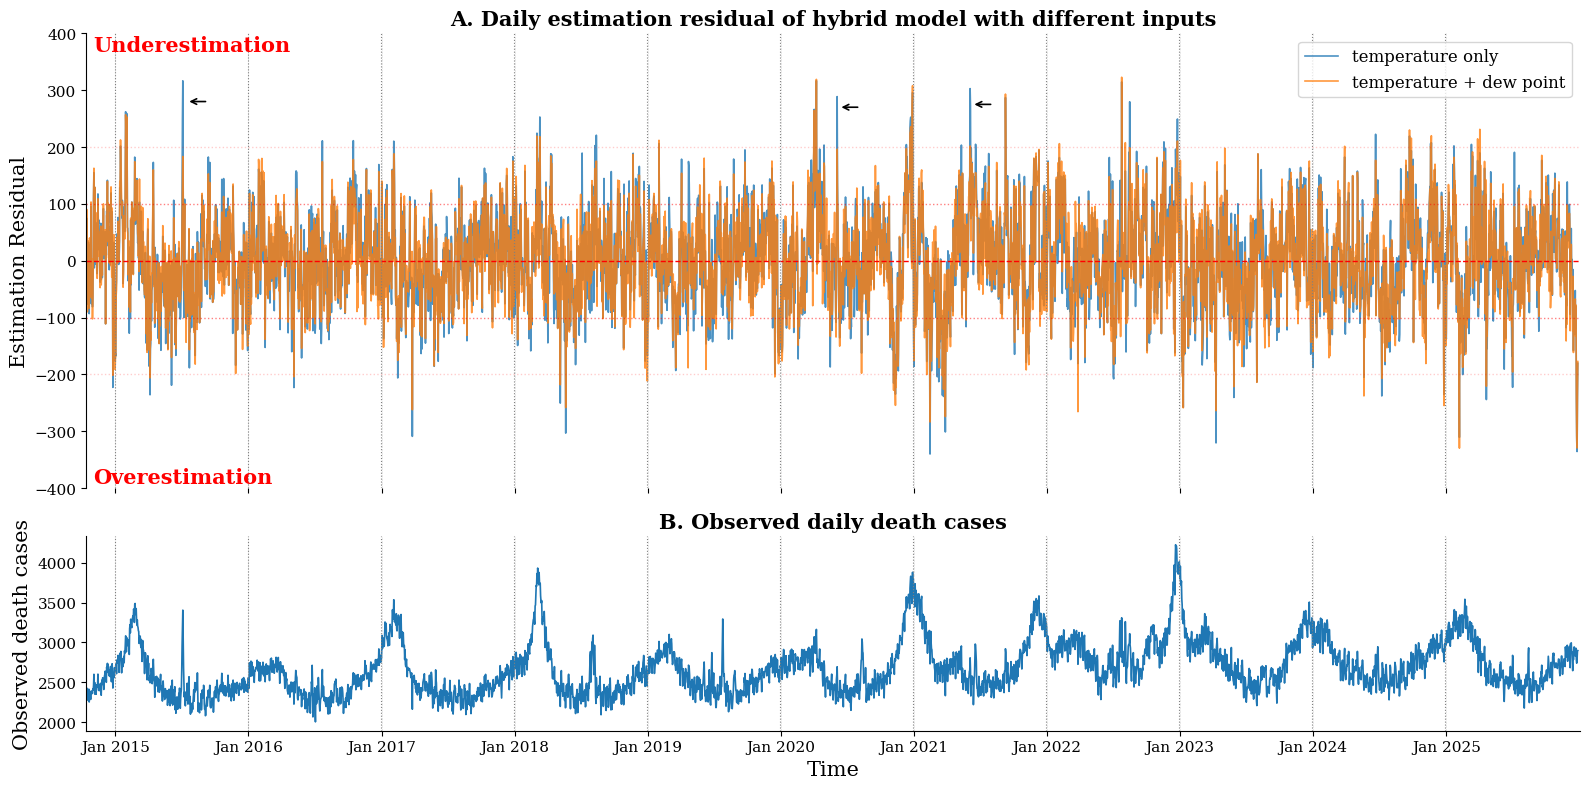

In [18]:
days_cumulative = 80
ticks = []
for year in range(2015, 2026):
    ticks.append(days_cumulative)  # Store the start of each year
    # Add days based on whether it's a leap year
    days_in_year = 366 if (year % 4 == 0 and (year % 100 != 0 or year % 400 == 0)) else 365
    days_cumulative += days_in_year

# x range (assumes len(val) >= 3800 as in your code)
xmax = 4100
x = np.arange(xmax)

fig, axes = plt.subplots(2, 1, figsize=(16,8), sharex=True, gridspec_kw={'height_ratios': [7, 3]})

# --- Panel A: estimation error ---
ax = axes[0]
ax.plot((val - tr['tas_only'])[:xmax], lw=1.2, label='temperature only', alpha=0.8)
ax.plot((val - tr['baseline_adaptive'])[:xmax], lw=1.2, label='temperature + dew point', alpha=0.8)

# reference lines
ax.axhline(0, color='red', lw=1.0, ls='--')
for y, a in [(100, 0.5), (200, 0.2)]:
    ax.axhline(y,  color='red', lw=1, ls=':', alpha=a)
    ax.axhline(-y, color='red', lw=1, ls=':', alpha=a)

# seasonal separators
for j in range(11):
    ax.axvline(j*365 + 80, color='grey', lw=0.8, ls=':')

# region labels
ax.text(20, -0.95*400,  "Overestimation",  color='red', fontsize=15, va='center', ha='left', fontweight='semibold')
ax.text(20, 0.95*400,  "Underestimation", color='red', fontsize=15, va='center', ha='left', fontweight='semibold')

# style
ax.set_xlim(0, xmax)
ax.set_ylim(-400, 400)
ax.grid(True, axis='x', ls='--', lw=0.5, alpha=0.4)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_ylabel('Estimation Residual', fontsize=15)
ax.set_title('A. Daily estimation residual of hybrid model with different inputs', fontsize=15)
ax.legend(loc='upper right', fontsize=12)

ax.annotate(
    "",
    xy=(275, 280), xycoords='data',
    xytext=(275 + 60, 280), textcoords='data',
    arrowprops=dict(arrowstyle='->', lw=1.2, color='black')
)

ax.annotate(
    "",
    xy=(2065, 270), xycoords='data',
    xytext=(2065 + 60, 270), textcoords='data',
    arrowprops=dict(arrowstyle='->', lw=1.2, color='black')
)

ax.annotate(
    "",
    xy=(2430, 275), xycoords='data',
    xytext=(2430 + 60, 275), textcoords='data',
    arrowprops=dict(arrowstyle='->', lw=1.2, color='black')
)

# --- Panel B: observed values (pure val) ---
ax2 = axes[1]
ax2.plot(val[:xmax], lw=1.2)
for j in range(11):
    ax2.axvline(j*365 + 80, color='grey', lw=0.8, ls=':')

ax2.grid(True, axis='x', ls='--', lw=0.5, alpha=0.4)
ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)
ax2.set_ylabel('Observed death cases', fontsize=15)
ax2.set_title('B. Observed daily death cases', fontsize=15)

# shared x labels/ticks

ax2.set_xlabel('Time', fontsize=15)
axes[1].set_xticks(ticks)
axes[1].set_xticklabels([f"Jan {year}" for year in range(2015, 2026)])

plt.tight_layout()
# plt.savefig("comparison_tas_dew_point.png", dpi=300, bbox_inches='tight')
plt.show()


## Residuals and respiratory-infection inputs

National non-COVID SARI and COVID-19-associated SARI incidence are aligned with hybrid-model residuals and temperature. This view supports visual checks for residual winter structure not captured by the fitted components.

In [19]:
sari_path = DATA_DIR / 'sari' / model['baseline_adaptive'].config.sari_filename
influenza_file = sari_path
df_sari = pd.read_csv(influenza_file, sep='\t')
df_covid = df_sari[df_sari.SARI=='COVID-19']
df_total = df_sari[df_sari.SARI=='Gesamt']
covid_00 =  df_covid[df_covid.Altersgruppe=='00+'].iloc[::-1,-1].to_numpy()
total_00 = df_total[df_total.Altersgruppe=='00+'].iloc[::-1, -1].to_numpy()[2:]
flu_00 = df_sari[df_sari.SARI=='Influenza'].iloc[::-1, -1].to_numpy()
covid_offset = total_00.shape[0] - covid_00.shape[0]
covid_00 = np.concatenate([np.zeros(covid_offset), covid_00])
flu_offset = total_00.shape[0] - flu_00.shape[0]
flu_00 = np.concatenate([np.zeros(flu_offset), flu_00])
sari_incidence = torch.tensor(total_00 - covid_00)
covid_incidence = torch.tensor(covid_00)
flu_incidence = torch.tensor(flu_00)


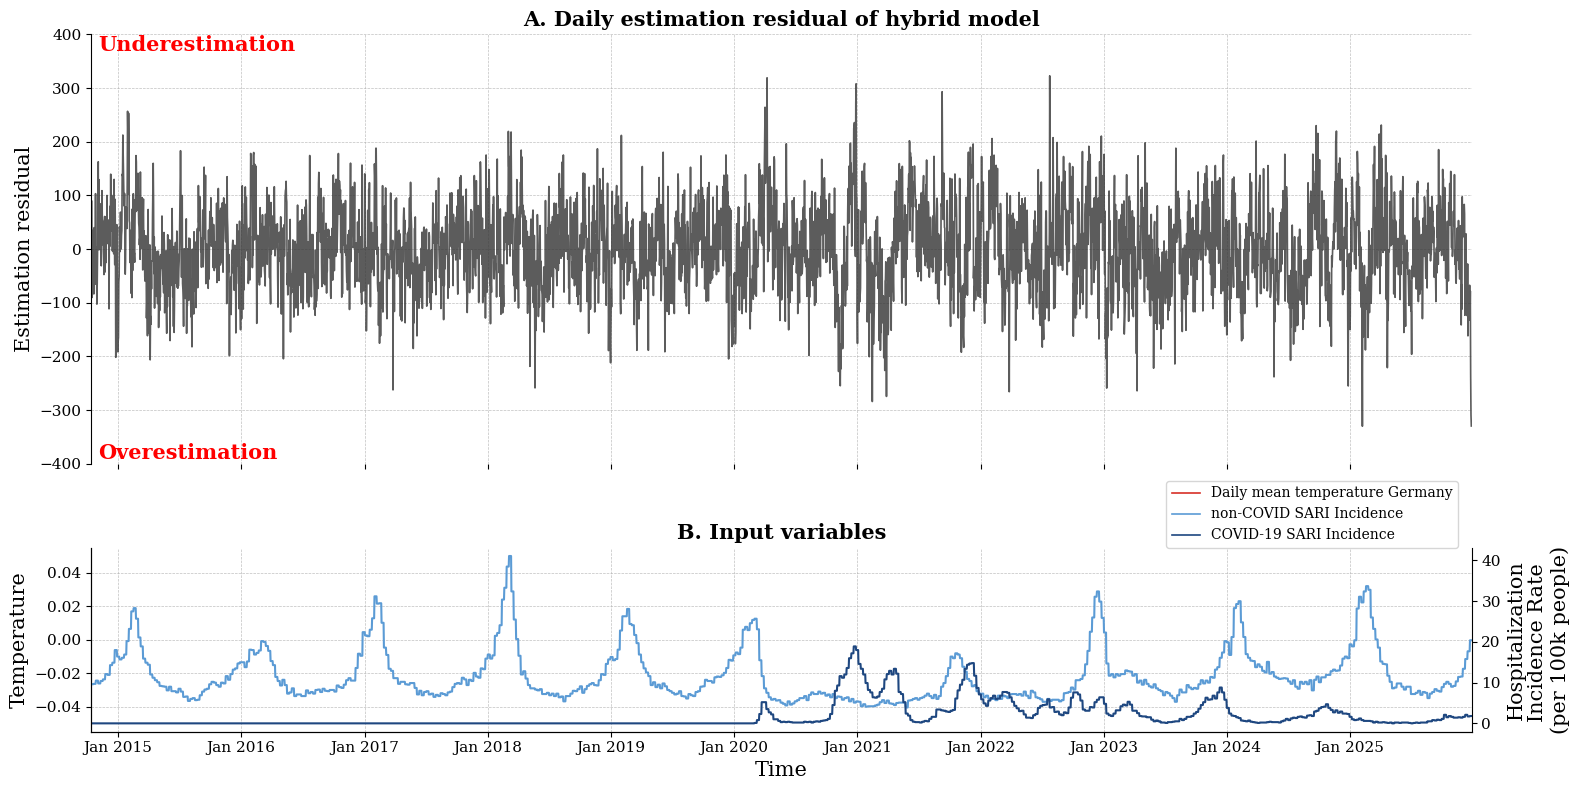

In [20]:
from matplotlib.lines import Line2D

t_day = model['tas_only'].temperature_input.mean(0)[5:].cpu()

# x range (assumes len(val) >= 3731 as in your code)
xmax = 3731 + 362
x = np.arange(xmax)

fig, axes = plt.subplots(2, 1, figsize=(16,8), sharex=True, gridspec_kw={'height_ratios': [7, 3]})

# --- Panel A: estimation error ---
ax = axes[0]
ax.plot((val - tr['baseline_adaptive'])[:xmax], lw=1.2, label='residual', alpha=0.8, color='0.2')

# region labels
ax.text(20, -0.95*400,  "Overestimation",  color='red', fontsize=15, va='center', ha='left', fontweight='semibold')
ax.text(20, 0.95*400,  "Underestimation", color='red', fontsize=15, va='center', ha='left', fontweight='semibold')

# style
ax.set_xlim(0, xmax)
ax.set_ylim(-400, 400)
ax.grid(True, axis='both', ls='--', lw=0.5, alpha=0.8)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_ylabel('Estimation residual', fontsize=15)
ax.set_title('A. Daily estimation residual of hybrid model', fontsize=15)
# ax.legend(loc='upper right', fontsize=12)

# --- Panel B: observed values (pure val) ---
ax2 = axes[1]
ax2.plot(t_day, lw=1.5, color= "#D73027" )

ax_twin = ax2.twinx()
ax_twin.plot(sari_incidence.repeat_interleave(7)[:xmax], color="#5B9BD5", lw=1.5)
ax_twin.plot(covid_incidence.repeat_interleave(7)[:xmax], color='#1E4780', lw=1.5)
ax_twin.set_ylabel('Hospitalization\nIncidence Rate \n(per 100k people)', fontsize=15)

ax_twin.spines['top'].set_visible(False)


ax2.grid(True, axis='both', ls='--', lw=0.5, alpha=0.8)
ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)
ax2.set_ylabel('Temperature', fontsize=15)
ax2.set_title('B. Input variables', fontsize=15)

# shared x labels/ticks

ax2.set_xlabel('Time', fontsize=15)
axes[1].set_xticks(ticks)
axes[1].set_xticklabels([f"Jan {year}" for year in range(2015, 2026)])

custom_lines = [
    Line2D([0], [0], color="#D73027", linestyle="-"),  
    Line2D([0], [0], color="#5B9BD5", linestyle="-"), 
    Line2D([0], [0], color="#1E4780", linestyle="-"),   # Men
]

legend_labels = [
    "Daily mean temperature Germany",
    "non-COVID SARI Incidence",
    "COVID-19 SARI Incidence",
]


# 线型 legend（Registered / Baseline）放在左上角第一幅图
ax2.legend(
    custom_lines,
    legend_labels,
    loc="upper right",
    fontsize=10,
    bbox_to_anchor=(0.995, 1.4),
)

plt.tight_layout()
# plt.savefig("residual_input.png", dpi=300, bbox_inches='tight')
plt.show()


## Temperature and relative-humidity diagnostics

Dew-point temperature is converted to relative humidity to compare national mean weather conditions with mortality residuals. These panels are descriptive diagnostics and do not replace the controlled response analysis in the temperature-humidity notebook.

In [9]:
a = 17.27
b = 237.7  # Celsius

def dew_point(T, RH=50):
    alpha = (a * T / (b + T)) + torch.log(RH/100)
    Td = (b * alpha) / (a - alpha)
    return Td

def rel_hum(T, Td):
    alpha = (a * Td / (b + Td)) - (a * T / (b + T))
    RH = 100 * torch.exp(alpha)
    return RH

t_day = model['baseline_adaptive'].temperature_input[:, 0, 5:].cpu()
t_dew_day = model['baseline_adaptive'].temperature_input[:, 1, 5:].cpu()
t_rh_day = rel_hum(t_day, t_dew_day)

t_day = t_day.mean(0)
t_dew_day = t_dew_day.mean(0)
t_rh_day = t_rh_day.mean(0)

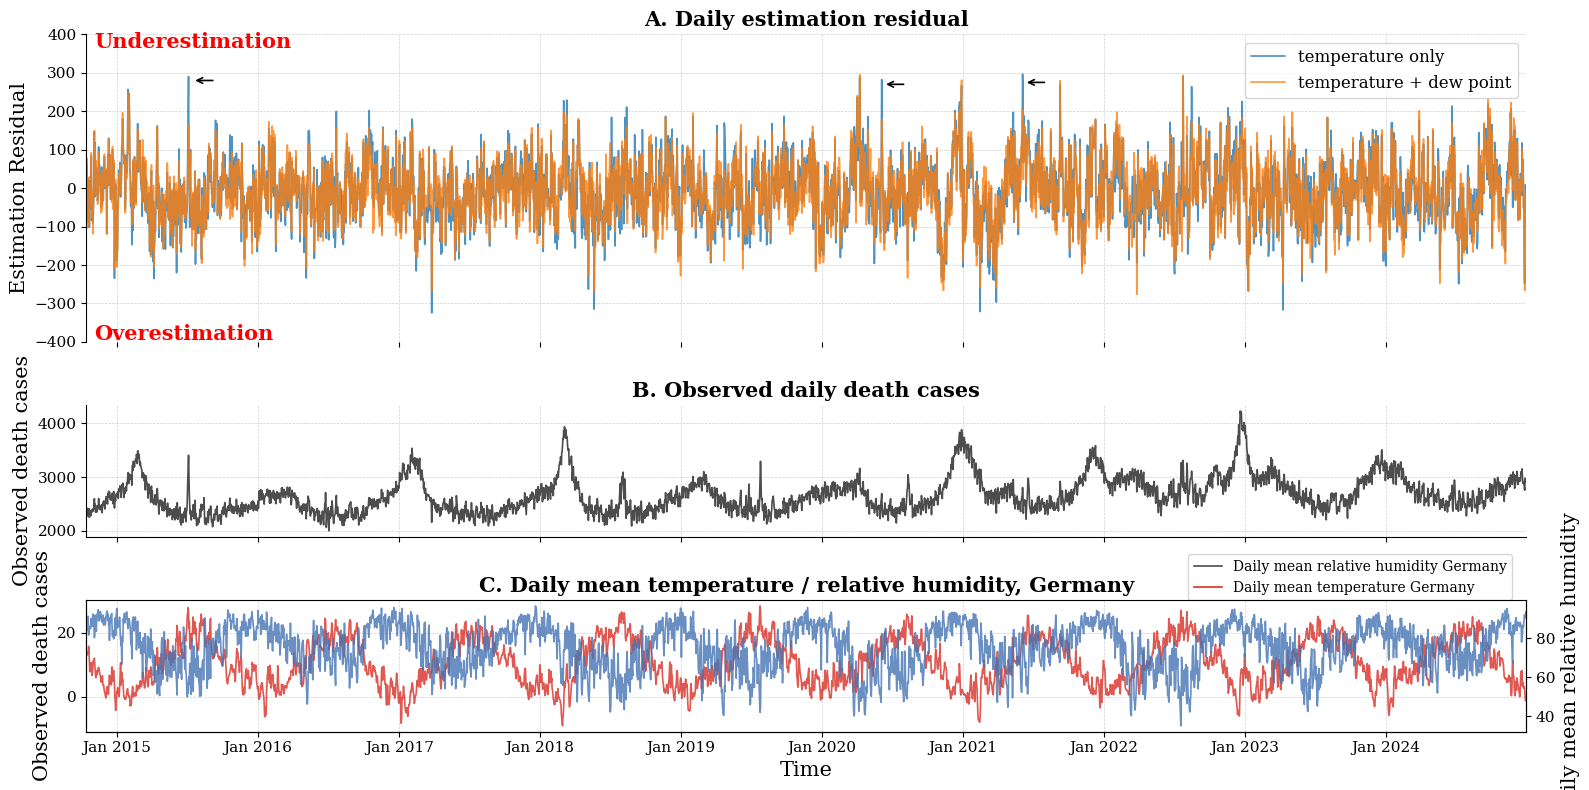

In [10]:
from tkinter import font
from turtle import color
import matplotlib.pyplot as plt
import numpy as np



# x range (assumes len(val) >= 3800 as in your code)
xmax = 3731
x = np.arange(xmax)

fig, axes = plt.subplots(3, 1, figsize=(16,8), sharex=True, gridspec_kw={'height_ratios': [7, 3, 3]})

# --- Panel A: estimation error ---
ax = axes[0]
ax.plot((val - tr['tas_only'])[:xmax], lw=1.2, label='temperature only', alpha=0.8)
ax.plot((val - tr['baseline_adaptive'])[:xmax], lw=1.2, label='temperature + dew point', alpha=0.8)

# region labels
ax.text(20, -0.95*400,  "Overestimation",  color='red', fontsize=15, va='center', ha='left', fontweight='semibold')
ax.text(20, 0.95*400,  "Underestimation", color='red', fontsize=15, va='center', ha='left', fontweight='semibold')

# style
ax.set_xlim(0, xmax)
ax.set_ylim(-400, 400)
ax.grid(True, axis='both', ls='--', lw=0.5, alpha=0.6)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_ylabel('Estimation Residual', fontsize=15)
ax.set_title('A. Daily estimation residual', fontsize=15)
ax.legend(loc='upper right', fontsize=12)

ax.annotate(
    "",
    xy=(275, 280), xycoords='data',
    xytext=(275 + 60, 280), textcoords='data',
    arrowprops=dict(arrowstyle='->', lw=1.2, color='black')
)

ax.annotate(
    "",
    xy=(2065, 270), xycoords='data',
    xytext=(2065 + 60, 270), textcoords='data',
    arrowprops=dict(arrowstyle='->', lw=1.2, color='black')
)

ax.annotate(
    "",
    xy=(2430, 275), xycoords='data',
    xytext=(2430 + 60, 275), textcoords='data',
    arrowprops=dict(arrowstyle='->', lw=1.2, color='black')
)

# --- Panel B: observed values (pure val) ---
ax2 = axes[1]
ax2.plot(val[:xmax], lw=1.2, color='0.3')


ax2.grid(True, axis='both', ls='--', lw=0.5, alpha=0.6)
ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)
ax2.set_ylabel('Observed death cases', fontsize=15)
ax2.set_title('B. Observed daily death cases', fontsize=15)

ax3 = axes[2]
ax3.plot(t_day[:xmax], lw=1.2, color='#D73027', alpha=0.8)

ax_twin = ax3.twinx()
ax_twin.plot(t_rh_day[:xmax], lw=1.2, color='#4575B4', alpha=0.8)
ax_twin.set_ylabel('Daily mean relative humidity', fontsize=15)

ax3.grid(True, axis='both', ls='--', lw=0.5, alpha=0.6)
ax3.spines['top'].set_visible(False)
ax3.set_ylabel('Observed death cases', fontsize=15)
ax3.set_title('C. Daily mean temperature / relative humidity, Germany', fontsize=15)


axes[2].set_xlabel('Time', fontsize=15)
axes[2].set_xticks(ticks)
axes[2].set_xticklabels([f"Jan {year}" for year in range(2015, 2025)])

custom_lines = [
    Line2D([0], [0], color="0.3", linestyle="-"),  
    Line2D([0], [0], color="#D73027", linestyle="-"), 
]

legend_labels = [
    "Daily mean relative humidity Germany",
    "Daily mean temperature Germany",
]


# 线型 legend（Registered / Baseline）放在左上角第一幅图
axes[2].legend(
    custom_lines,
    legend_labels,
    loc="upper right",
    fontsize=10,
    bbox_to_anchor=(0.995, 1.4),
)

plt.tight_layout()
# plt.savefig("comparison_tas_dew_point.png", dpi=300, bbox_inches='tight')
# plt.show()
